# Pendahuluan

Di dalam material ini, kamu akan mempelajari dataset klasifikasi dan melakukan elaborasi data (preprocessing, EDA, feature selection, dan dimensionality reduction). Jalankan setiap sel secara berurutan.

## Introduction to Capstone Project

[Tulis latar belakang dan tujuan bisnis sesuai dataset yang kamu gunakan.]

**Problem Statement**

[Tulis masalah yang ingin diselesaikan sesuai dataset yang kamu gunakan.]

**About Datasets**

[Isi: sumber dataset (link Kaggle/UCI), jumlah baris dan kolom, serta penjelasan setiap kolom dan target 0 = negatif, 1 = positif.]

**Objective of Capstone 1**

Tujuan dari Capstone adalah melakukan data preprocessing termasuk Exploratory Data Analysis untuk menggali insight dari data pasien penderita penyakit jantung hingga proses feature selection dan dimensionality reduction. Hasil akhir yang ingin dicapai yaitu mendapatkan insight data penderita penyakit jantung dan data yang siap untuk dimodelkan pada tahap selanjutnya.

**Metrics**

[Tulis metrics yang dipantau, misalnya jumlah kasus positif, proporsi per kategori, rata-rata fitur utama pada kasus positif, dan korelasi fitur terhadap target.]

**Persiapan**

Disini kita akan menyiapkan libraries yang diperlukan dan dataset berdasarkan link: 
Dalam rangka mengetahui tentang dataset, kita akan melihat overview.

In [52]:
#Import libraries
import numpy as np
import pandas as pd
import math
import random
import seaborn as sns
from scipy.stats import pearsonr, jarque_bera
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [53]:
d = pd.read_csv(DATA_PATH)
print(d.shape)
print(d.columns.tolist())
print(d.isna().sum())
d.head()

(569, 33)
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [54]:
# ===== PENGATURAN DATASET (sesuaikan bila perlu) =====
DATA_PATH = "archive/data_mentah.csv"   # atau "archive/data.csv"
TARGET    = 'diagnosis'
POSITIVE  = 'M'                          # M (malignant) = 1, B (benign) = 0
DROP_COLS = ['Unnamed: 32']

# Memuat dataset dari file lokal
data = pd.read_csv(DATA_PATH)

# Membuang kolom indeks/ID bawaan
auto_drop = [c for c in data.columns if c.lower() in ('id', 'unnamed: 0', 'index')]
data = data.drop(columns=list(set(DROP_COLS + auto_drop)))


# Menyamakan nama kolom target menjadi 'target' dan nilainya menjadi 0/1
if TARGET is None:
    TARGET = data.columns[-1]
data = data.rename(columns={TARGET: 'target'})
data = data.dropna(subset=['target'])
kelas = sorted(data['target'].unique(), key=str)
assert len(kelas) == 2, f"Target harus biner, ditemukan kelas: {kelas}"
if POSITIVE is None:
    POSITIVE = kelas[1]
data['target'] = (data['target'] == POSITIVE).astype(int)
print(f"Target '{TARGET}': {kelas} -> kelas positif (1) = {POSITIVE}")

# Menampilkan lima baris teratas
data.head()

Target 'diagnosis': ['B', 'M'] -> kelas positif (1) = M


,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [55]:
# Menampilkan lima baris terbawah
data.tail()

,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
564,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,1,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400
568,0,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,...,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039


In [56]:
# Melihat jumlah dataset (jumlah baris dan kolom)
data.shape

(569, 31)

In [57]:
# Melihat columns apa saja yang ada dalam dataset
data.columns

Index(['target', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

In [58]:
# Melihat persebaran data
data.describe()

,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,0.372583,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,0.483918,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,0.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,0.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,0.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,1.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,1.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [59]:
# Melihat uniqueness data
data.nunique()

target                       2
radius_mean                456
texture_mean               479
perimeter_mean             522
area_mean                  539
smoothness_mean            474
compactness_mean           537
concavity_mean             537
concave points_mean        542
symmetry_mean              432
fractal_dimension_mean     499
radius_se                  540
texture_se                 519
perimeter_se               533
area_se                    528
smoothness_se              547
compactness_se             541
concavity_se               533
concave points_se          507
symmetry_se                498
fractal_dimension_se       545
radius_worst               457
texture_worst              511
perimeter_worst            514
area_worst                 544
smoothness_worst           411
compactness_worst          529
concavity_worst            539
concave points_worst       492
symmetry_worst             500
fractal_dimension_worst    535
dtype: int64

In [60]:
# Melihat informasi dari dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   target                   569 non-null    int64  
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

**Data Quality**

Disini kita akan melakukan pengecekan karakter, handling missing value, outlier, duplikat dan data imbalance serta skewness.

In [61]:
# Melakukan handling kolom menjadi kategorikal
# Kolom bertipe teks atau dengan nilai unik <= 6 dianggap kategorikal (target ikut dimasukkan)
lst = [c for c in data.columns if c == 'target' or not pd.api.types.is_numeric_dtype(data[c]) or data[c].nunique() <= 6]
print("Kolom kategorikal:", lst)
data[lst] = data[lst].astype(object)

# Melihat perubahan
data.dtypes

Kolom kategorikal: ['target']


target                      object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst            float64
concave points_worst

In [62]:
# Pelabelan target (kolom kategorikal lain mempertahankan nilai aslinya)
data['target'] = data['target'].replace({0: 'No disease',
                                         1: 'Disease'})
data['target'].value_counts()

target
No disease    357
Disease       212
Name: count, dtype: int64

In [63]:
# Pisahkan numerical dan categorical
numerical_col = data.select_dtypes(exclude=['object'])
categorical_col = data.select_dtypes(include=['object'])

In [64]:
# Pengecekan karakter dari data kategorikal
for i in categorical_col:
    print("Berikut ini merupakan informasi: {} dengan {}".format(i, data[i].unique()))
    print()

Berikut ini merupakan informasi: target dengan ['Disease' 'No disease']



**Pengecekan nilai tidak valid**

Periksa nilai yang tidak mungkin ada pada fitur (misalnya nilai 0 pada tekanan darah, kolesterol, glukosa, atau BMI). Nilai tersebut diubah menjadi NaN, lalu diisi pada tahap handling missing value.

In [65]:
# Melihat jumlah data per item pada setiap kolom kategorikal
for c in categorical_col:
    print(data[c].value_counts(dropna=False), "\n")

# Petunjuk: jumlah nilai 0 pada kolom numerik (nilai 0 mungkin tidak valid)
print("Jumlah nilai 0 per kolom numerik:")
print((numerical_col == 0).sum()[(numerical_col == 0).sum() > 0])

target
No disease    357
Disease       212
Name: count, dtype: int64 

Jumlah nilai 0 per kolom numerik:
concavity_mean          13
concave points_mean     13
concavity_se            13
concave points_se       13
concavity_worst         13
concave points_worst    13
dtype: int64


[Tulis temuan: kolom mana yang memiliki nilai tidak valid dan berapa jumlahnya.]

In [66]:
# Isi sesuai temuan di atas: {'nama_kolom': [nilai_tidak_valid]}
# Contoh: INVALID_VALUES = {'Cholesterol': [0], 'RestingBP': [0]}
INVALID_VALUES = {}

# Menemukan baris dengan nilai tidak valid
for col, vals in INVALID_VALUES.items():
    print(col, "->", data[col].isin(vals).sum(), "baris")

In [67]:
# Ganti nilai tidak valid menjadi NaN
for col, vals in INVALID_VALUES.items():
    data.loc[data[col].isin(vals), col] = np.nan

In [68]:
# Cek kembali apakah masih ada nilai tidak valid
for col, vals in INVALID_VALUES.items():
    print(col, "->", data[col].isin(vals).sum(), "baris tersisa")

Selanjutnya kita akan handling missing value.

In [69]:
# Check missing values
print("Hasil missing value:\n", data.isna().sum())

Hasil missing value:
 target                     0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


In [70]:
# Mengisi missing value: kolom kategorikal dengan modus, kolom numerik dengan median
for c in data.columns:
    if data[c].isna().any():
        if data[c].dtype == 'object':
            data[c] = data[c].fillna(data[c].mode()[0])
        else:
            data[c] = data[c].fillna(data[c].median())

In [71]:
# Check missing values kembali
print("Hasil missing value:\n", data.isna().sum())

Hasil missing value:
 target                     0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


Kita akan melakukan pengecekan rows yang duplikat.

In [72]:
# Memeriksa duplikat data
data.duplicated().sum()

np.int64(0)

In [73]:
# Menampilkan baris data duplicate
data[data.duplicated()]

,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst


Berdasarkan output diatas, kamu perlu melakukan drop duplikat data agar tidak ada data yang duplikat dalam dataset.

In [74]:
# Menghapus data duplikat
data.drop_duplicates(keep='first', inplace=True)

# Memeriksa ulang duplikat data
data.duplicated().sum()

np.int64(0)

Selanjutnya kita akan menampilkan outliers dan menghapus data yang outlier.

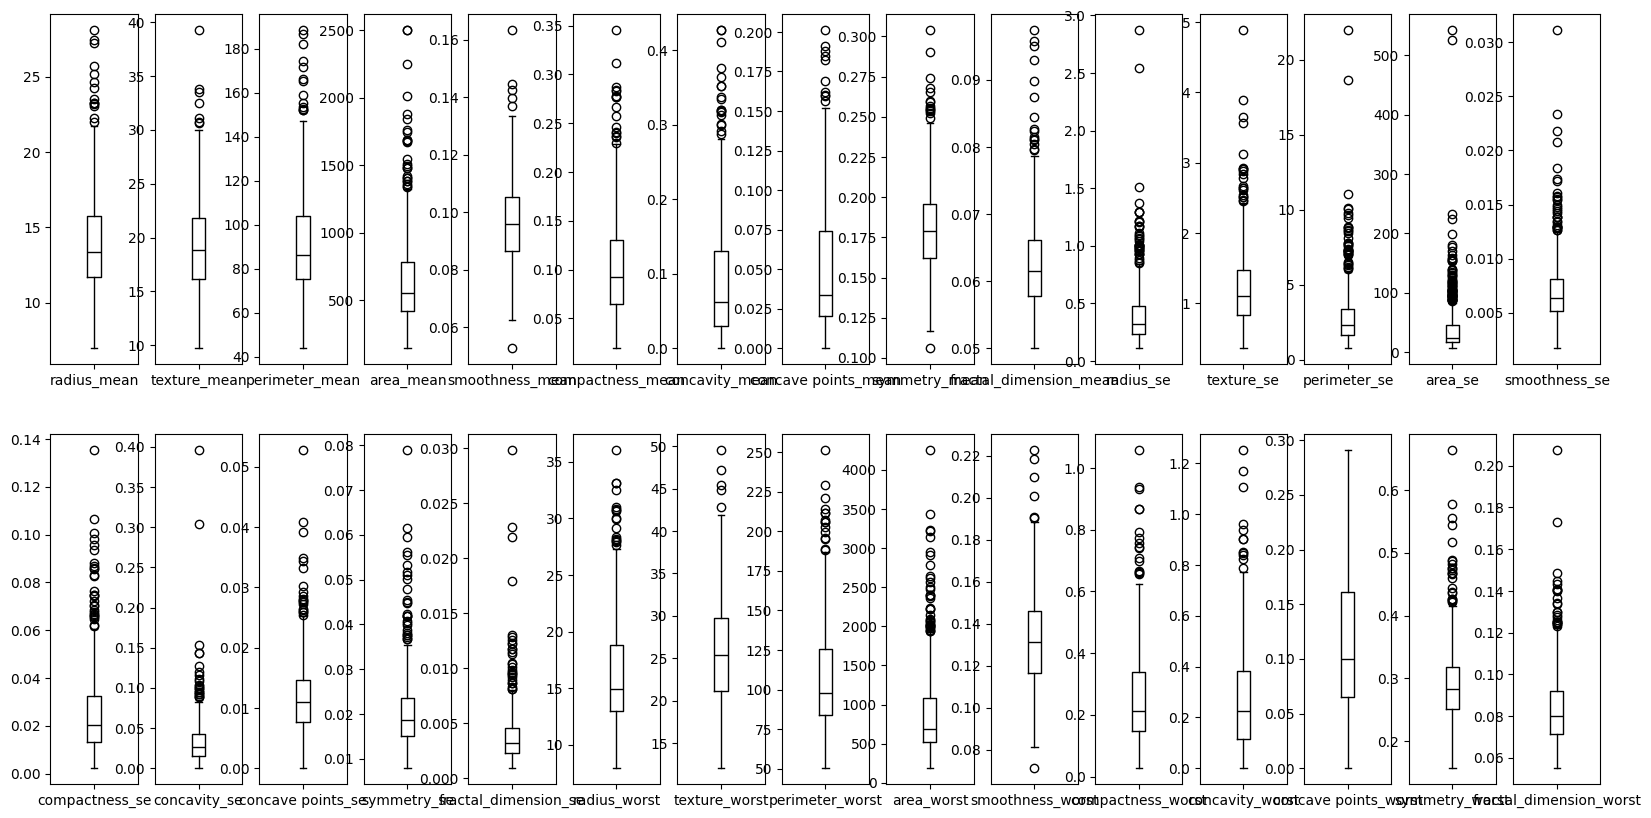

In [75]:
# Menyegarkan pembagian kolom setelah pembersihan
numerical_col = data.select_dtypes(exclude=['object'])
categorical_col = data.select_dtypes(include=['object'])

# Menampilkan boxplot untuk melihat outliers data numerik
n = numerical_col.shape[1]
numerical_col.plot(kind='box', subplots=True, layout=(2, math.ceil(n/2)), sharex=False, sharey=False, figsize=(20, 10), color='k')
plt.show()

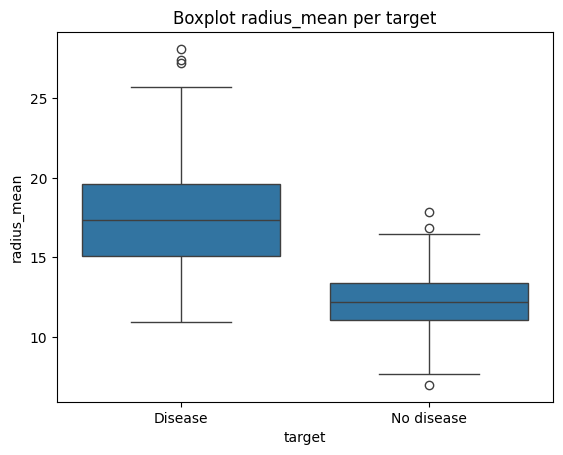

In [76]:
# Menampilkan data berdasarkan target untuk salah satu fitur numerik (ganti nama kolom bila perlu)
fitur_box = numerical_col.columns[0]
sns.boxplot(x='target', y=fitur_box, data=data)
plt.title(f'Boxplot {fitur_box} per target')
plt.show()

[Tulis kolom kontinu mana yang memiliki outlier berdasarkan boxplot.]

In [77]:
# Mencari tahu data yang outliers dengan mendefinisikan fungsi
continous_features = list(numerical_col.columns)
print("Fitur kontinu:", continous_features)

def outliers(data_out, drop = False):
    for each_feature in data_out.columns:
        feature_data = data_out[each_feature]
        Q1 = np.percentile(feature_data, 25.) 
        Q3 = np.percentile(feature_data, 75.) 
        IQR = Q3-Q1 
        outlier_step = IQR * 1.5 
        outliers = feature_data[~((feature_data >= Q1 - outlier_step) & (feature_data <= Q3 + outlier_step))].index.tolist()  
        if not drop:
            print('For the feature {}, Num of Outliers is {}'.format(each_feature, len(outliers)))
        if drop:
            data.drop(outliers, inplace = True, errors = 'ignore')
            print('Outliers from {} feature removed'.format(each_feature))

# Menampilkan data yang outlier
outliers(data[continous_features])

Fitur kontinu: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
For the feature radius_mean, Num of Outliers is 14
For the feature texture_mean, Num of Outliers is 7
For the feature perimeter_mean, Num of Outliers is 13
For the feature area_mean, Num of Outliers is 25
For the feature smoothness_mean, Num of Outliers is 6
For the feature compactness_mean, Num of Outliers is 16
For the feature concavity_mean, Num of Outliers is 18
For the feature concave points_mean, Num of Outliers is 10
For the fea

In [78]:
# Menghapus outlier dengan fungsi sebelumnya
outliers(data[continous_features], drop=True)
print("Ukuran data setelah outlier dihapus:", data.shape)

Outliers from radius_mean feature removed
Outliers from texture_mean feature removed
Outliers from perimeter_mean feature removed
Outliers from area_mean feature removed
Outliers from smoothness_mean feature removed
Outliers from compactness_mean feature removed
Outliers from concavity_mean feature removed
Outliers from concave points_mean feature removed
Outliers from symmetry_mean feature removed
Outliers from fractal_dimension_mean feature removed
Outliers from radius_se feature removed
Outliers from texture_se feature removed
Outliers from perimeter_se feature removed
Outliers from area_se feature removed
Outliers from smoothness_se feature removed
Outliers from compactness_se feature removed
Outliers from concavity_se feature removed
Outliers from concave points_se feature removed
Outliers from symmetry_se feature removed
Outliers from fractal_dimension_se feature removed
Outliers from radius_worst feature removed
Outliers from texture_worst feature removed
Outliers from perimeter

Melihat informasi dari kategori dari data kategorikal. 

In [79]:
# Jumlah kategori pada salah satu fitur kategorikal (ganti nama kolom bila perlu)
kat = [c for c in categorical_col.columns if c != 'target']
if kat:
    data[kat[0]].value_counts().plot(kind='bar')
    plt.title(f'Distribusi {kat[0]}')
    plt.show()

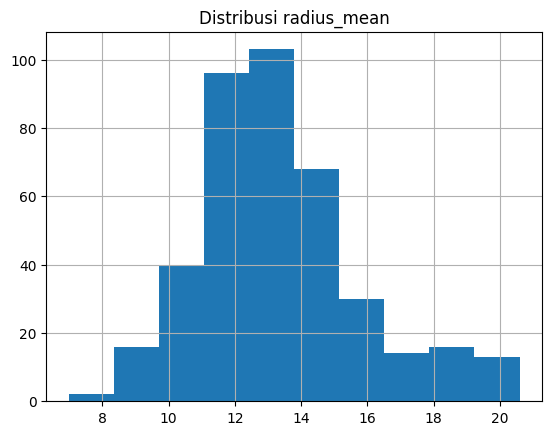

In [80]:
# Distribusi salah satu fitur numerik (ganti nama kolom bila perlu)
data[continous_features[0]].hist()
plt.title(f'Distribusi {continous_features[0]}')
plt.show()

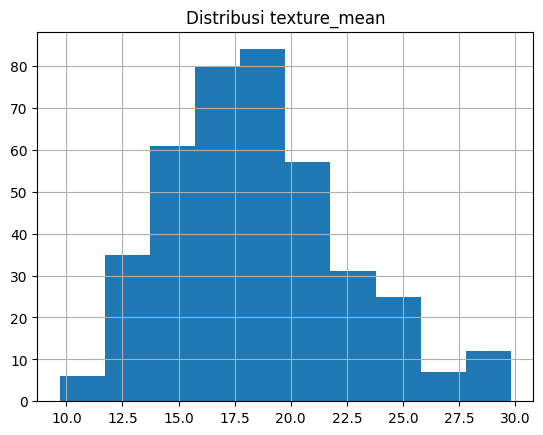

In [81]:
# Distribusi fitur lain (kategorikal kedua bila ada, jika tidak numerik kedua)
if len(kat) > 1:
    data[kat[1]].value_counts().plot(kind='bar')
    plt.title(f'Distribusi {kat[1]}')
else:
    data[continous_features[min(1, len(continous_features)-1)]].hist()
    plt.title(f'Distribusi {continous_features[min(1, len(continous_features)-1)]}')
plt.show()

Selanjutnya kita akan melakukan pengecekan data, apakah target imbalance?

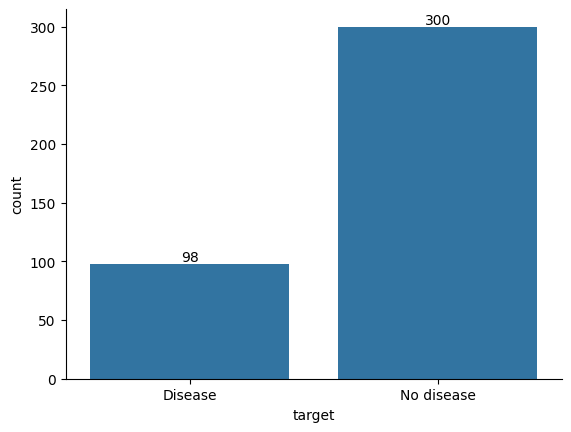

target
No disease    0.754
Disease       0.246
Name: proportion, dtype: float64


In [82]:
# Memeriksa data imbalance
ax = sns.countplot(x='target', data=data)
for label in ax.containers:
    ax.bar_label(label)
sns.despine()
plt.show()
print(data['target'].value_counts(normalize=True).round(3))

[Tulis interpretasi: apakah target seimbang atau imbalance, dengan persentase tiap kelas.]

**Periksa statistik deskriptif dari kumpulan data (rata-rata, distribusi, dll)**

In [83]:
# Melihat statistik deskriptif dari data
data.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,...,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,13.376209,18.505879,86.403266,570.547990,0.093271,0.086260,0.060442,0.035902,0.173639,0.061211,...,15.087623,24.723015,98.640477,728.471608,0.128684,0.211521,0.213448,0.096333,0.279092,0.079529
std,2.484104,3.911148,16.841597,222.883241,0.012066,0.034979,0.049068,0.025625,0.020819,0.005015,...,3.232713,5.635779,22.129399,329.649485,0.020253,0.107702,0.147218,0.049968,0.043539,0.012479
min,6.981000,9.710000,43.790000,143.500000,0.062510,0.019380,0.000000,0.000000,0.116700,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.081250,0.034320,0.000000,0.000000,0.178300,0.055210
25%,11.710000,15.702500,75.065000,420.350000,0.084520,0.059592,0.025628,0.018640,0.159000,0.057337,...,13.015000,20.385000,83.922500,516.025000,0.113900,0.136100,0.104825,0.061492,0.247725,0.070195
50%,12.995000,18.175000,84.065000,518.300000,0.092385,0.079455,0.045580,0.028295,0.172250,0.060855,...,14.395000,24.585000,93.905000,632.500000,0.128900,0.188300,0.181100,0.084985,0.275750,0.078030
75%,14.640000,20.755000,94.730000,664.200000,0.101750,0.108975,0.083572,0.049478,0.188500,0.064213,...,16.457500,28.435000,109.775000,830.575000,0.141775,0.265575,0.304350,0.128700,0.307325,0.086570
max,20.590000,29.810000,137.800000,1320.000000,0.125700,0.202200,0.254500,0.125900,0.245900,0.078180,...,24.560000,40.540000,166.400000,1872.000000,0.187800,0.611000,0.772700,0.254300,0.412800,0.120500


[Tulis ringkasan statistik deskriptif: rata-rata dan rentang tiap fitur numerik.]

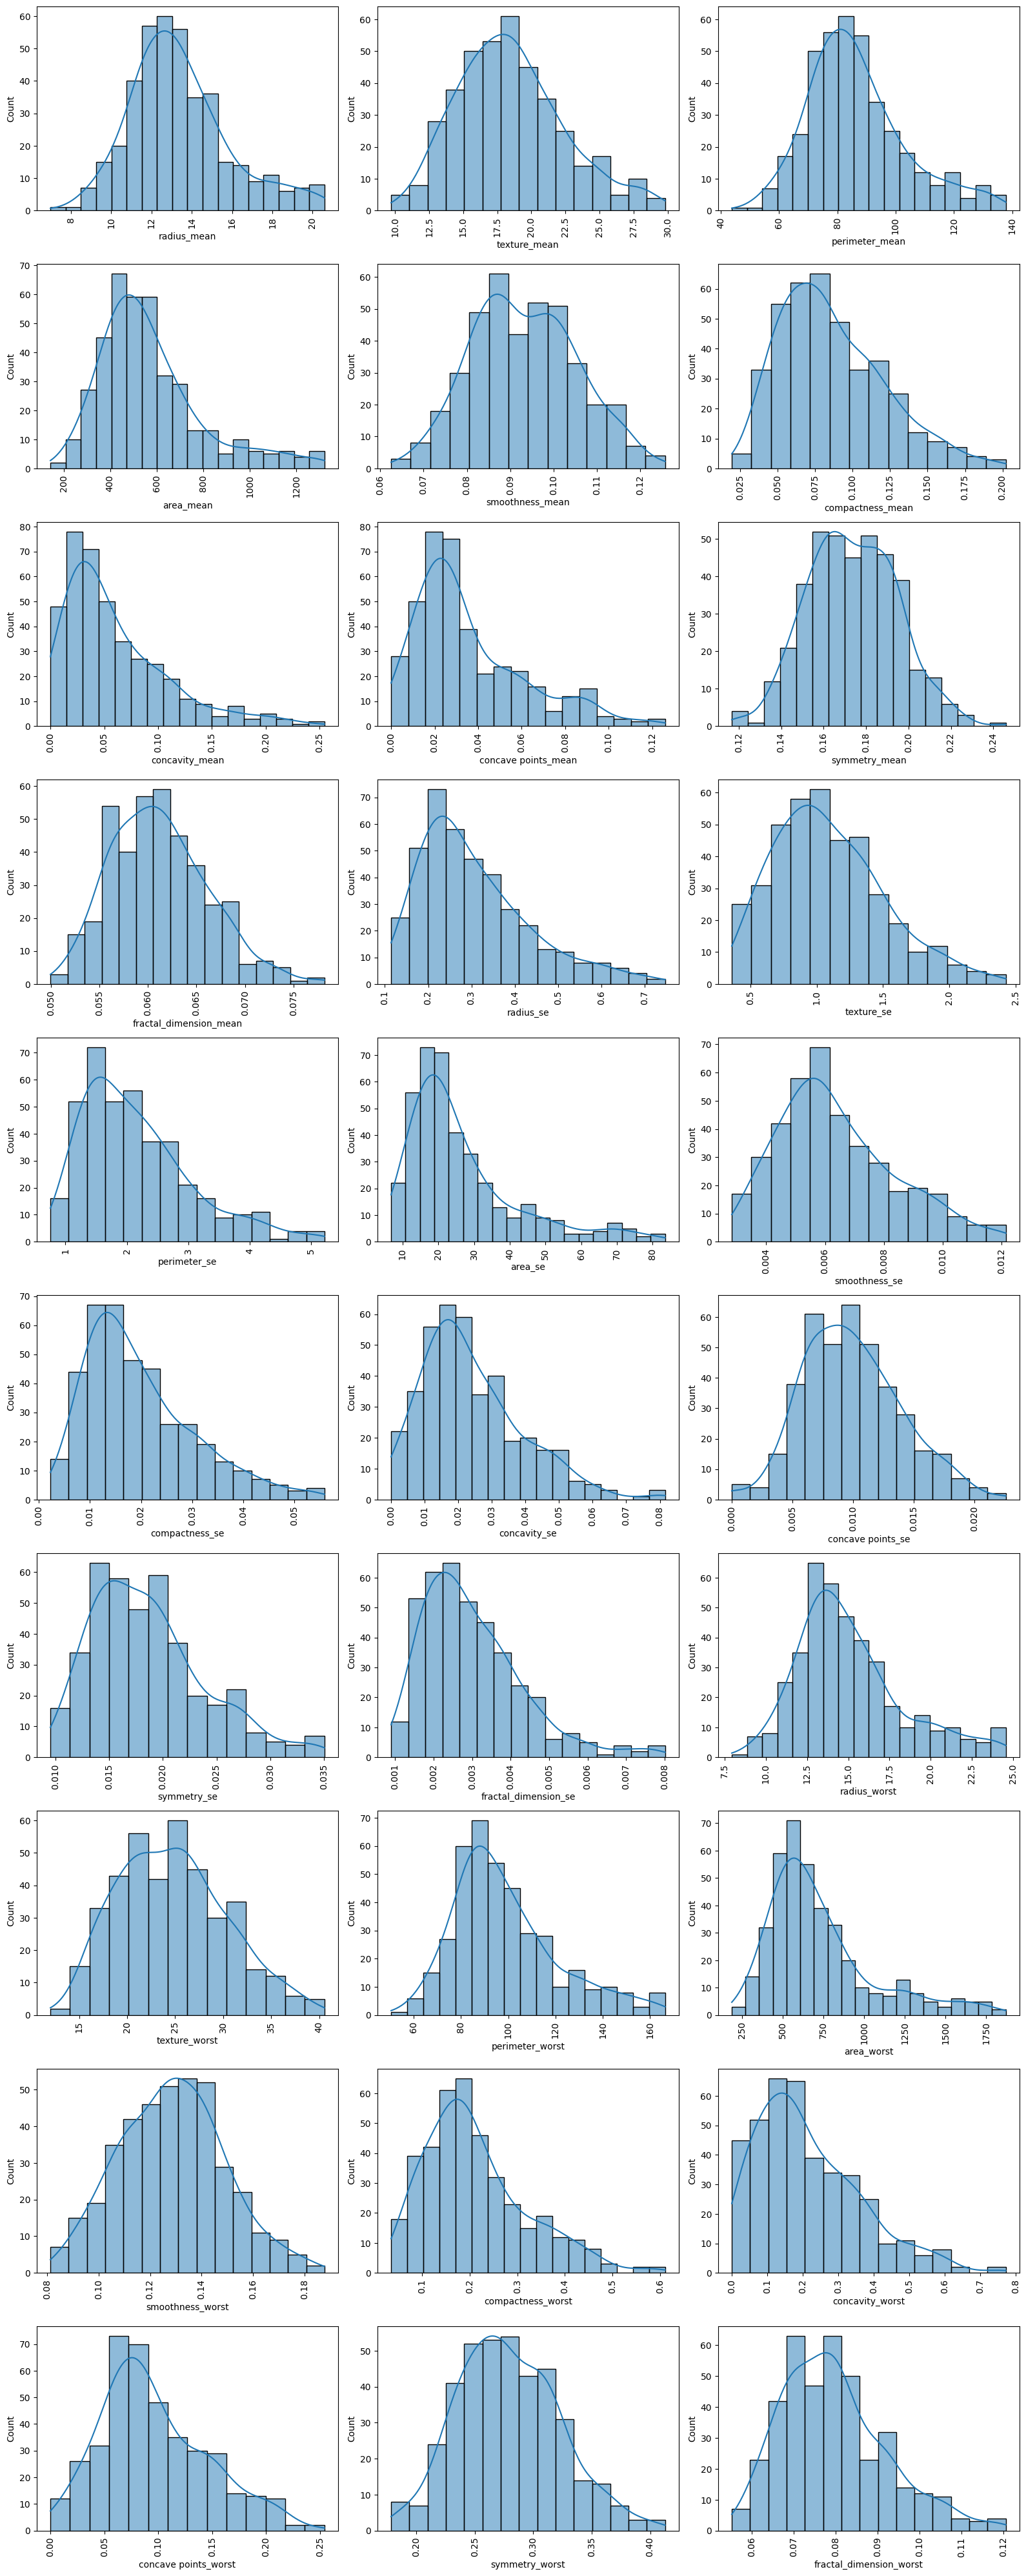

In [84]:
# Memvisualisasikan distribusi variabel numerical
numerical_col = data.select_dtypes(exclude=['object'])
n = numerical_col.shape[1]
plt.figure(figsize=(16, 4*math.ceil(n/3)))
for index,column in enumerate(numerical_col):
    plt.subplot(math.ceil(n/3),3,index+1)
    sns.histplot(data=numerical_col,x=column,kde=True)
    plt.xticks(rotation = 90)
plt.tight_layout(pad = 1.0)
plt.show()

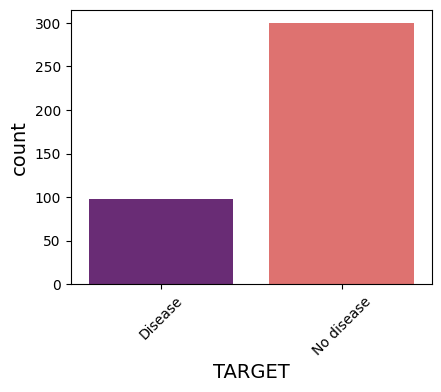

In [85]:
# Memvisualisasikan distribusi variabel kategorikal
categorical_col = data.select_dtypes(include=['object'])
n = categorical_col.shape[1]
plt.figure(figsize=(12, 4*math.ceil(n/3)))
for index, column in enumerate(categorical_col):
    plt.subplot(math.ceil(n/3), 3, index+1)
    sns.countplot(data=categorical_col,x=column, hue='target', palette='magma')
    plt.xlabel(str(column).upper(),fontsize=14)
    plt.ylabel("count", fontsize=14)
    plt.xticks(rotation=45)

plt.tight_layout(pad = 1.0)
plt.show()

Melihat korelasi antar feature.

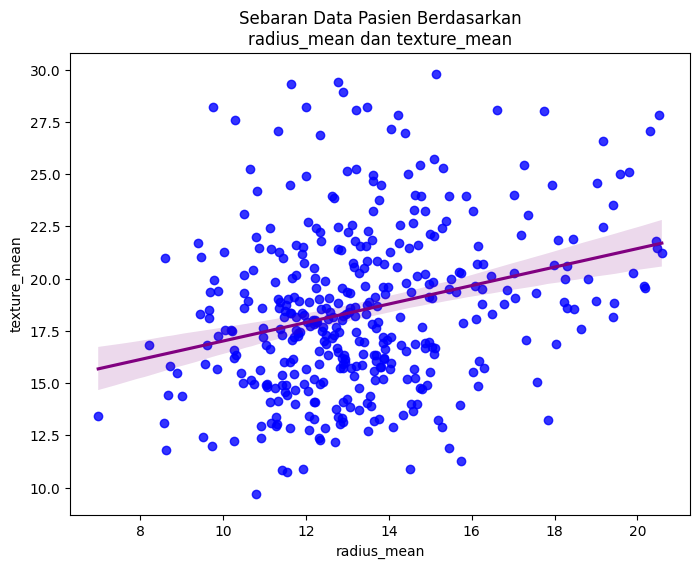

In [86]:
# Melihat korelasi antara dua fitur numerik (ganti fitur sesuai kebutuhan)
fa, fb = continous_features[0], continous_features[min(1, len(continous_features)-1)]
plt.figure(figsize = (8,6))
sns.regplot(x=data[fa], y=data[fb], scatter_kws = {'color':'blue'}, line_kws = {'color':'purple'})
plt.title(f'Sebaran Data Pasien Berdasarkan\n{fa} dan {fb}')
plt.show()

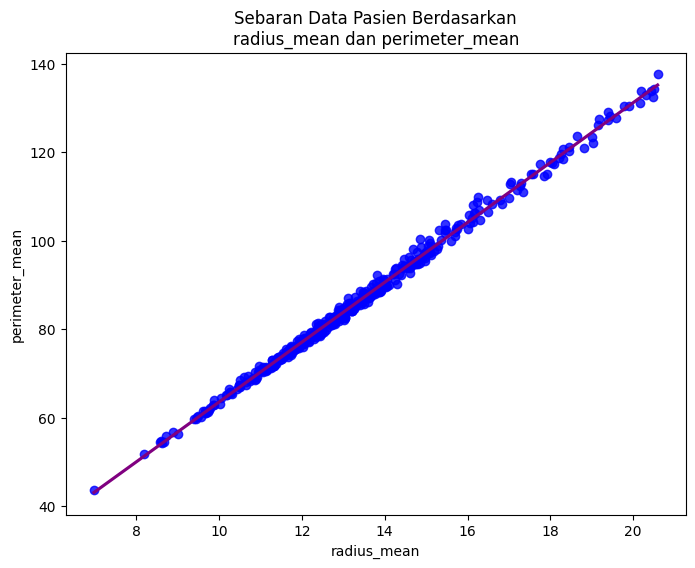

In [87]:
# Melihat korelasi antara pasangan fitur numerik lain
fc = continous_features[min(2, len(continous_features)-1)]
plt.figure(figsize = (8,6))
sns.regplot(x=data[fa], y=data[fc], scatter_kws = {'color':'blue'}, line_kws = {'color':'purple'})
plt.title(f'Sebaran Data Pasien Berdasarkan\n{fa} dan {fc}')
plt.show()

[Simpulkan dari grafik yang kamu dapatkan.]

In [88]:
# Simpan data yang sudah bersih dan berlabel
data.to_csv('data.csv')

# Melabeli kembali datanya menjadi angka
df = pd.read_csv('data.csv', index_col=0)
df['target'] = df['target'].replace({'No disease':0,'Disease':1}).astype(int)
kode_kategori = {}
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]):
        kode, uniques = pd.factorize(df[c])
        df[c] = kode
        kode_kategori[c] = {u: i for i, u in enumerate(uniques)}
print("Pemetaan kolom teks ke angka:", kode_kategori)
df.head()

Pemetaan kolom teks ke angka: {}


,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
6,1,18.25,19.98,119.6,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,...,22.88,27.66,153.2,1606.0,0.1442,0.2576,0.3784,0.19320,0.3063,0.08368
7,1,13.71,20.83,90.2,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,...,17.06,28.14,110.6,897.0,0.1654,0.3682,0.2678,0.15560,0.3196,0.11510
10,1,16.02,23.24,102.7,797.8,0.08206,0.06669,0.03299,0.03323,0.1528,...,19.19,33.88,123.8,1150.0,0.1181,0.1551,0.1459,0.09975,0.2948,0.08452
11,1,15.78,17.89,103.6,781.0,0.09710,0.12920,0.09954,0.06606,0.1842,...,20.42,27.28,136.5,1299.0,0.1396,0.5609,0.3965,0.18100,0.3792,0.10480
13,1,15.85,23.95,103.7,782.7,0.08401,0.10020,0.09938,0.05364,0.1847,...,16.84,27.66,112.0,876.5,0.1131,0.1924,0.2322,0.11190,0.2809,0.06287


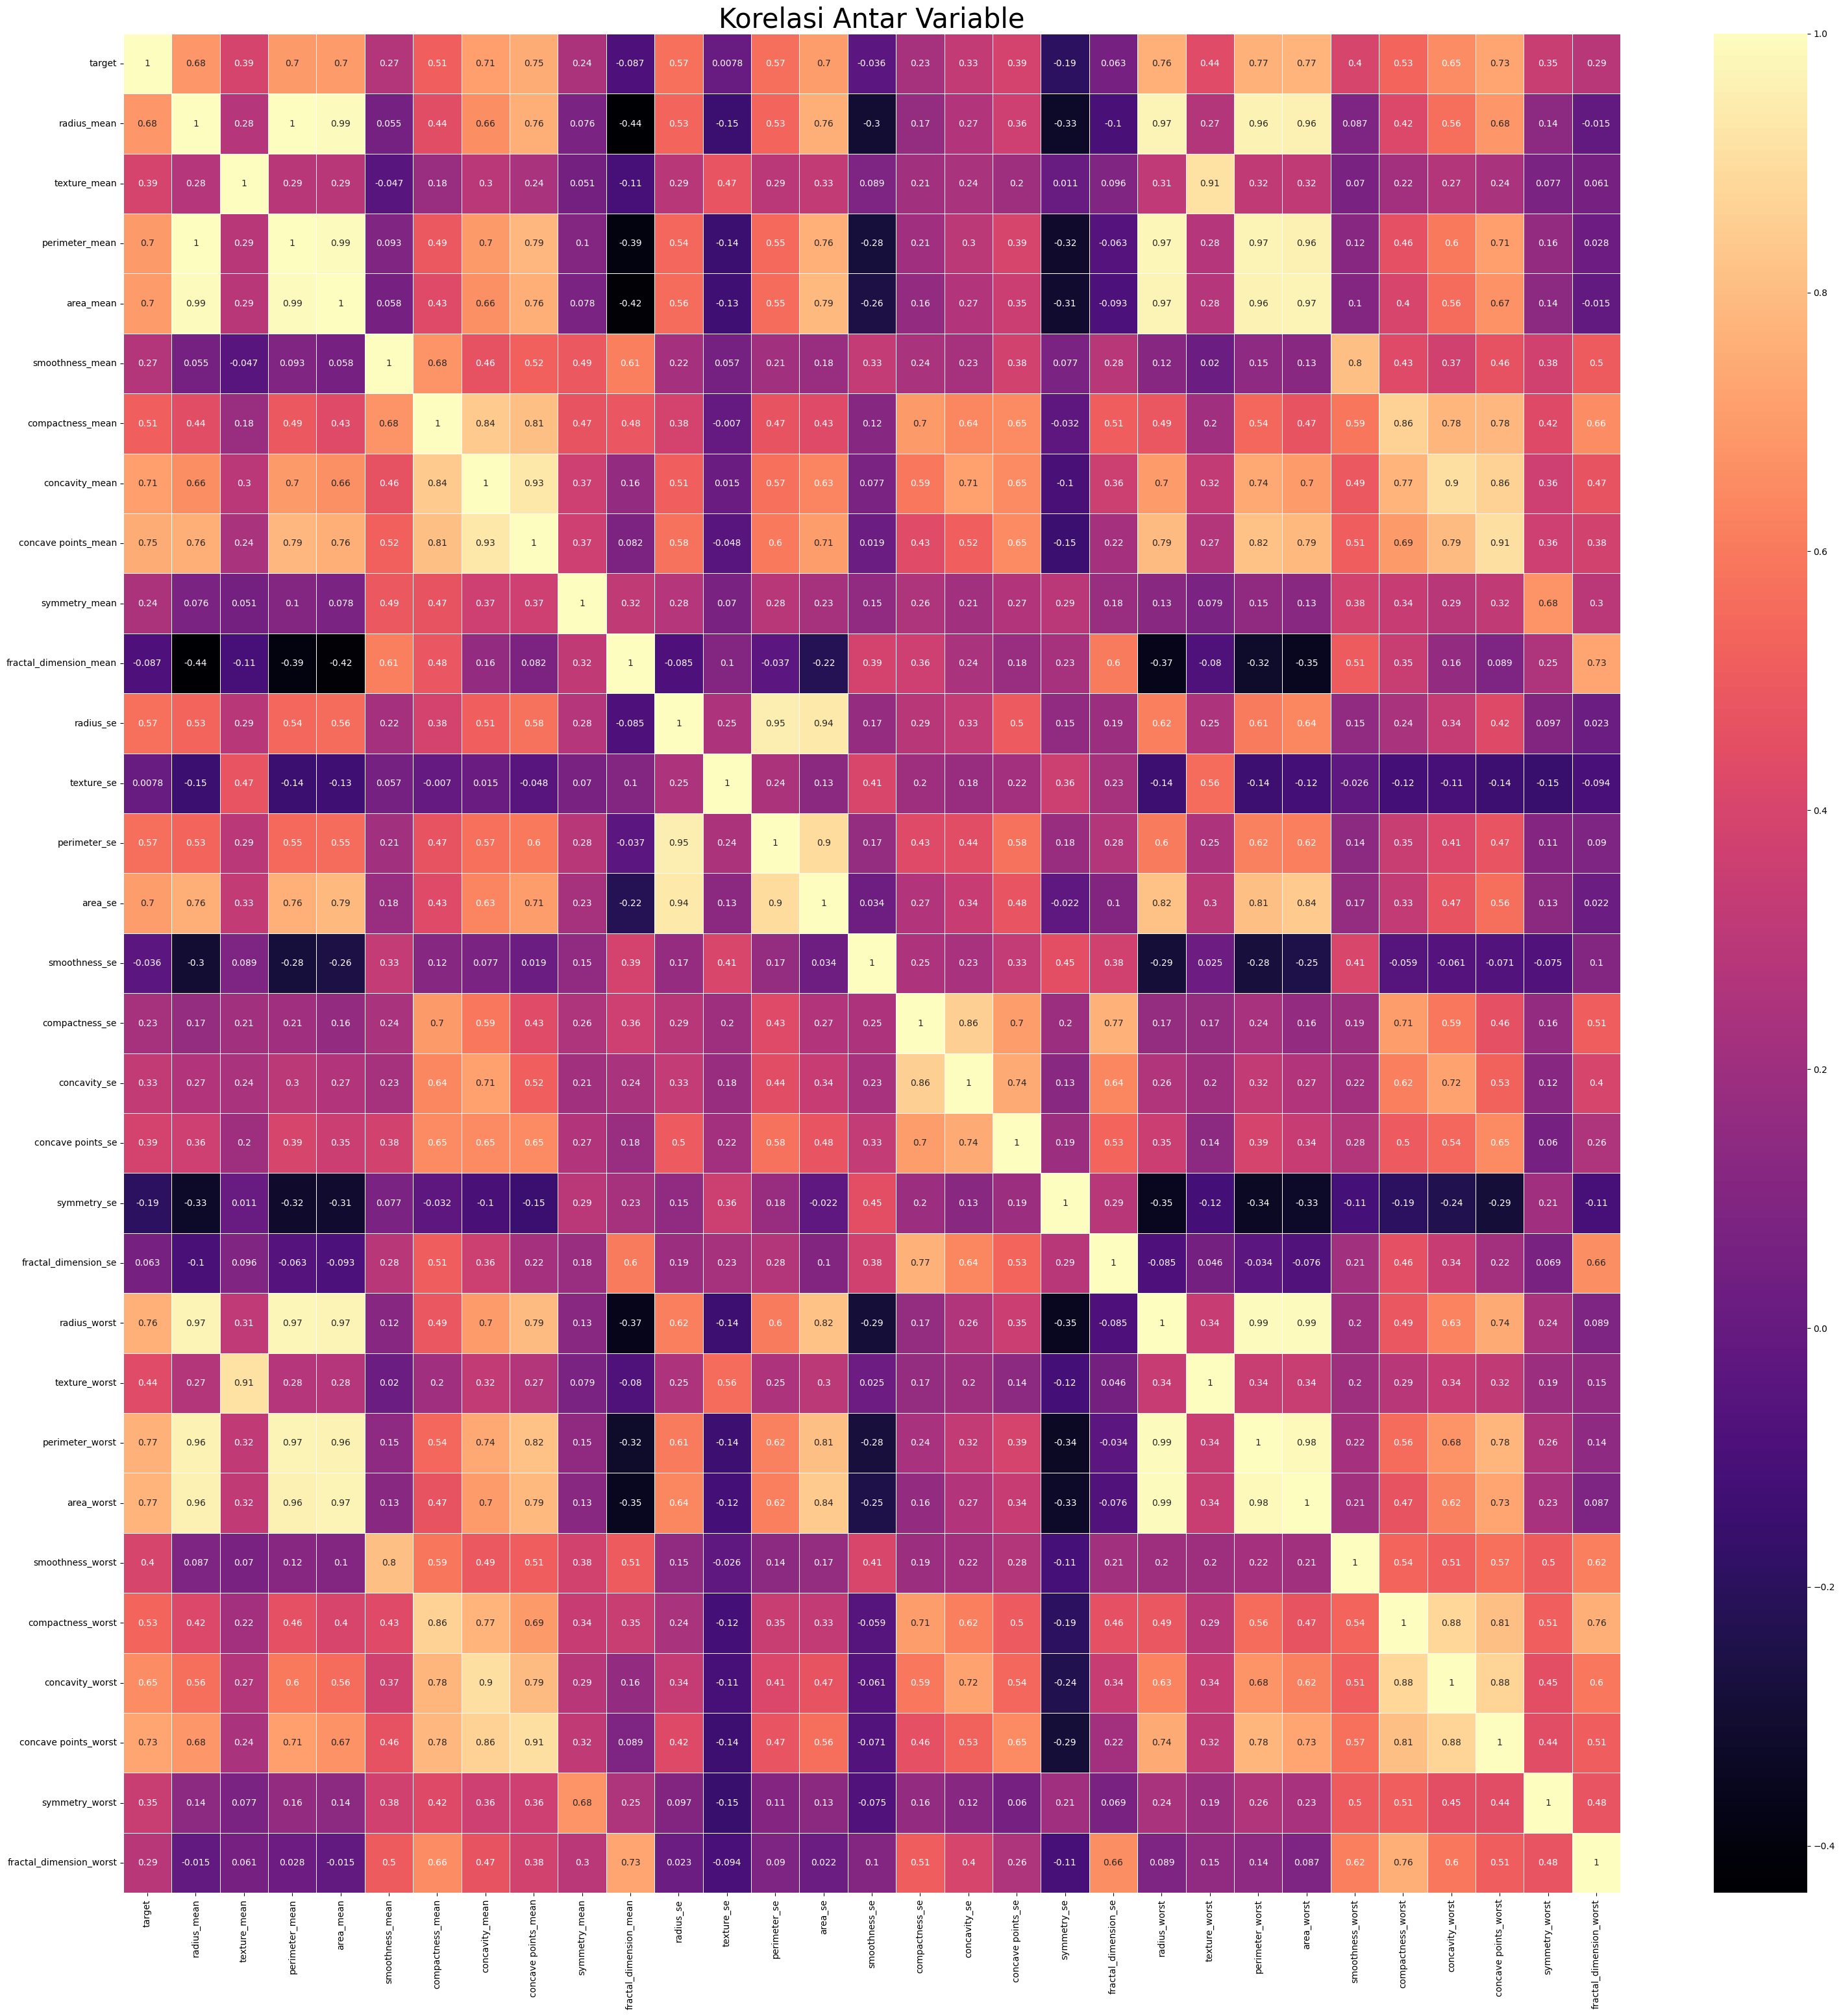

In [89]:
# melihat korelasi antar variable untuk mencari feature yang penting
plt.figure(figsize=(max(8, df.shape[1]*1.2), max(8, df.shape[1]*1.2)))
cor = df.corr()
sns.heatmap(cor,annot=True, linewidth=.5, cmap="magma")
plt.title('Korelasi Antar Variable', fontsize = 30)
plt.show()

In [90]:
cor_matrix = df.corr()
cor_matrix

,target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
target,1.000000,0.680705,0.388596,0.695835,0.698005,0.271570,0.514346,0.710567,0.752190,0.243588,...,0.761081,0.437909,0.768194,0.773626,0.396847,0.533996,0.653300,0.726639,0.347406,0.290821
radius_mean,0.680705,1.000000,0.280796,0.998113,0.992047,0.055311,0.442360,0.658031,0.755607,0.075653,...,0.971286,0.273847,0.964851,0.957772,0.087209,0.416464,0.563240,0.682235,0.137655,-0.014583
texture_mean,0.388596,0.280796,1.000000,0.285880,0.288688,-0.046879,0.181078,0.295111,0.239147,0.051037,...,0.311152,0.914721,0.316562,0.317755,0.069886,0.216026,0.274070,0.238186,0.076977,0.060915
perimeter_mean,0.695835,0.998113,0.285880,1.000000,0.990235,0.093196,0.492915,0.696240,0.785954,0.102371,...,0.972912,0.280552,0.971558,0.959710,0.121237,0.460901,0.599672,0.712906,0.160178,0.027877
area_mean,0.698005,0.992047,0.288688,0.990235,1.000000,0.058280,0.428703,0.664847,0.758145,0.077918,...,0.969353,0.280953,0.962721,0.971053,0.102255,0.400703,0.559618,0.671695,0.136700,-0.014754
smoothness_mean,0.271570,0.055311,-0.046879,0.093196,0.058280,1.000000,0.675183,0.463982,0.522678,0.494062,...,0.122928,0.020158,0.146367,0.125280,0.803945,0.432375,0.372220,0.463910,0.375969,0.504310
compactness_mean,0.514346,0.442360,0.181078,0.492915,0.428703,0.675183,1.000000,0.837473,0.805062,0.470457,...,0.487260,0.203987,0.543912,0.471562,0.588434,0.861979,0.780565,0.784528,0.424398,0.656342
concavity_mean,0.710567,0.658031,0.295111,0.696240,0.664847,0.463982,0.837473,1.000000,0.930271,0.365858,...,0.697135,0.323000,0.737467,0.701045,0.490384,0.772677,0.904941,0.861916,0.363584,0.470354
concave points_mean,0.752190,0.755607,0.239147,0.785954,0.758145,0.522678,0.805062,0.930271,1.000000,0.365482,...,0.792484,0.272741,0.816780,0.790517,0.509263,0.692292,0.794996,0.908179,0.360800,0.381099
symmetry_mean,0.243588,0.075653,0.051037,0.102371,0.077918,0.494062,0.470457,0.365858,0.365482,1.000000,...,0.128278,0.079260,0.148892,0.128689,0.381236,0.339391,0.292389,0.316389,0.675715,0.298244


In [91]:
#Mengurutkan korelasi
cor_matrix['target'].sort_values()

symmetry_se               -0.194890
fractal_dimension_mean    -0.086631
smoothness_se             -0.036030
texture_se                 0.007755
fractal_dimension_se       0.062799
compactness_se             0.229104
symmetry_mean              0.243588
smoothness_mean            0.271570
fractal_dimension_worst    0.290821
concavity_se               0.325974
symmetry_worst             0.347406
concave points_se          0.387972
texture_mean               0.388596
smoothness_worst           0.396847
texture_worst              0.437909
compactness_mean           0.514346
compactness_worst          0.533996
perimeter_se               0.565909
radius_se                  0.571842
concavity_worst            0.653300
radius_mean                0.680705
perimeter_mean             0.695835
area_mean                  0.698005
area_se                    0.703715
concavity_mean             0.710567
concave points_worst       0.726639
concave points_mean        0.752190
radius_worst               0

[Tulis interpretasi korelasi fitur terhadap target: mana yang kuat dan arahnya (positif/negatif).]

[Tulis kesimpulan dan fitur yang dipilih.]

In [92]:
# Memilih fitur dengan korelasi absolut tertinggi terhadap target (ubah K bila perlu)
K = min(9, df.shape[1]-1)
korelasi_target = cor_matrix['target'].drop('target').abs().sort_values(ascending=False)
variabel = korelasi_target.head(K).index.tolist()
print("Fitur terpilih:", variabel)
analyze = df[variabel]

Fitur terpilih: ['area_worst', 'perimeter_worst', 'radius_worst', 'concave points_mean', 'concave points_worst', 'concavity_mean', 'area_se', 'area_mean', 'perimeter_mean']


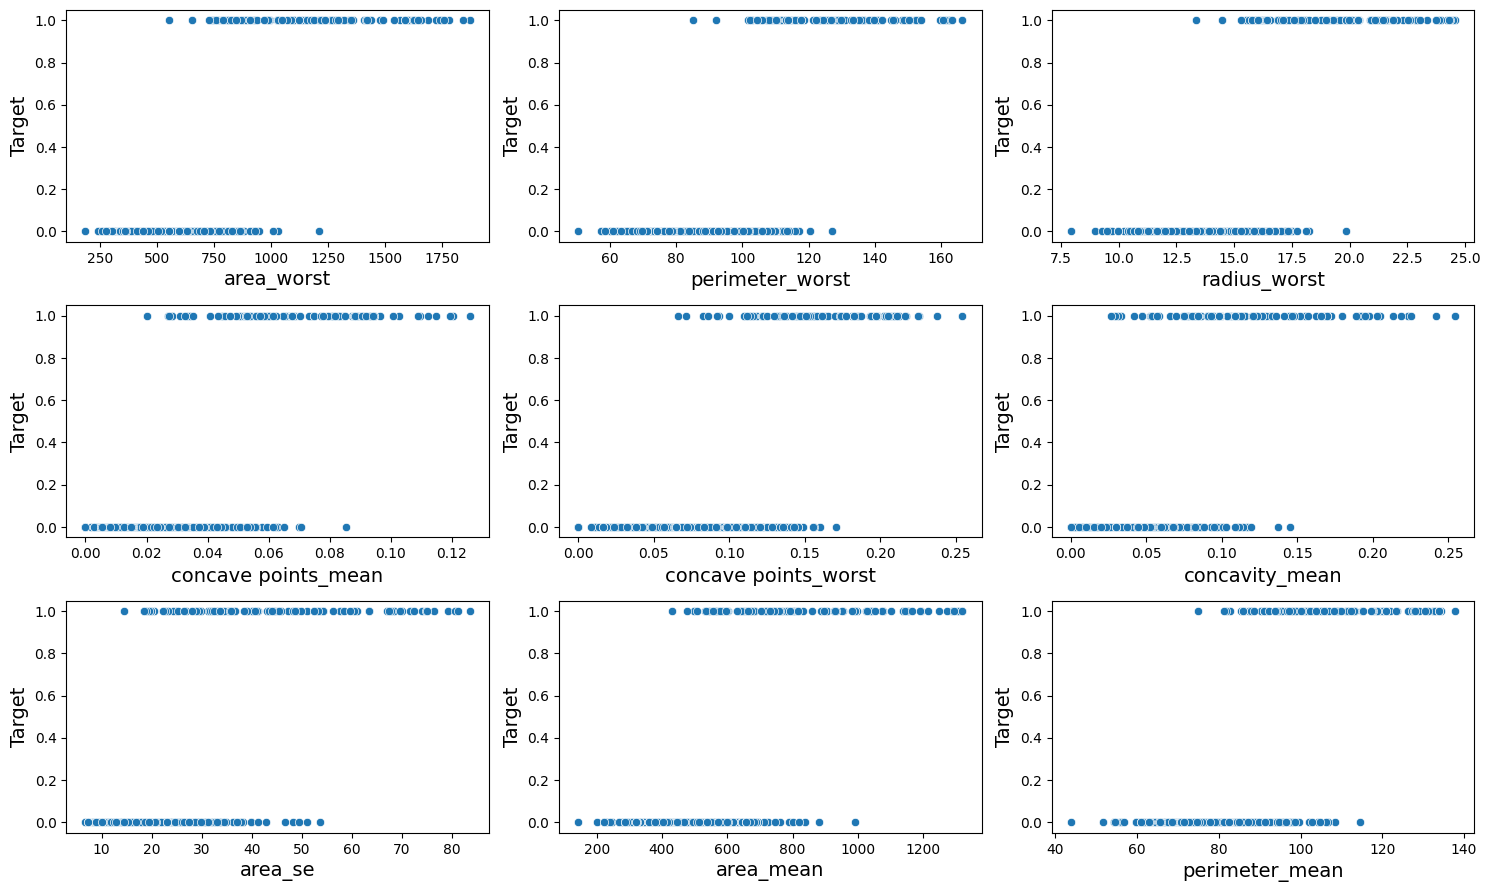

In [93]:
# Informasi variabel ke target
fig = plt.figure(figsize=(15, 3*math.ceil(len(analyze.columns)/3)))
for index in range(len(analyze.columns)):
    plt.subplot(math.ceil(len(analyze.columns)/3),3,index + 1)
    sns.scatterplot(x = analyze.iloc[:,index],y=df.target,data = analyze)
    plt.xlabel(analyze.columns[index], fontsize=14)
    plt.ylabel("Target", fontsize=14)

fig.tight_layout(pad = 1.0)

**Scaling data**

Scaling adalah suatu cara untuk membuat numerical data pada dataset memiliki rentang nilai (scale) yang sama. Tidak ada lagi satu variabel data yang mendominasi variabel data lainnya.

In [94]:
# Mendefinisikan standard scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop("target", axis=1))

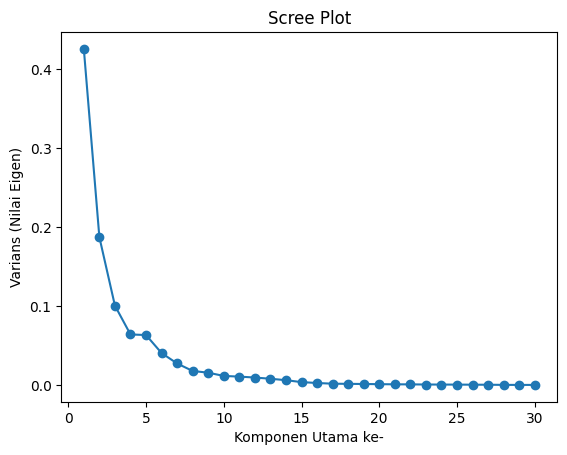

In [95]:
# Perform PCA for dimensionality reduction
feature_number = len(X_scaled[0])
pca = PCA(n_components=feature_number)

# Fit PCA with dataset
pca.fit(X_scaled)

# Get variance information
variance_ratio = pca.explained_variance_ratio_

# Calculate cummulative
cumulative_variance = np.cumsum(variance_ratio)

# Create Scree Plot
plt.plot(range(1, len(variance_ratio) + 1), variance_ratio, marker='o')
plt.xlabel('Komponen Utama ke-')
plt.ylabel('Varians (Nilai Eigen)')
plt.title('Scree Plot')
plt.show()

In [96]:
pca = PCA(n_components=min(9, X_scaled.shape[1]))
heart_data_reduced = pca.fit_transform(X_scaled)

In [97]:
feature_names = df.drop('target', axis=1).columns.to_list()
component_names = [f"PC{i+1}" for i in range(pca.n_components_)]

for component, component_name in zip(pca.components_, component_names):
    feature_indices = component.argsort()[::-1]
    retained_features = [feature_names[idx] for idx in feature_indices[:pca.n_components_]]
    print(f"{component_name}: {retained_features}")

PC1: ['concave points_mean', 'concavity_mean', 'concave points_worst', 'perimeter_worst', 'concavity_worst', 'radius_worst', 'area_worst', 'perimeter_mean', 'compactness_mean']
PC2: ['fractal_dimension_mean', 'fractal_dimension_se', 'fractal_dimension_worst', 'smoothness_mean', 'smoothness_se', 'compactness_se', 'smoothness_worst', 'compactness_mean', 'concavity_se']
PC3: ['texture_se', 'symmetry_se', 'radius_se', 'perimeter_se', 'smoothness_se', 'texture_mean', 'area_se', 'texture_worst', 'concave points_se']
PC4: ['symmetry_mean', 'smoothness_mean', 'symmetry_worst', 'smoothness_worst', 'symmetry_se', 'radius_se', 'smoothness_se', 'area_se', 'perimeter_se']
PC5: ['texture_worst', 'texture_mean', 'texture_se', 'symmetry_worst', 'smoothness_worst', 'fractal_dimension_worst', 'compactness_worst', 'concavity_worst', 'symmetry_mean']
PC6: ['symmetry_worst', 'symmetry_mean', 'symmetry_se', 'compactness_se', 'compactness_worst', 'concavity_se', 'concavity_worst', 'texture_mean', 'fractal_di